1 - Balayage

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from utilities_optimizer.model import DEFAULT_PARAMS, solve

prices = range(50, 251, 5)
rows = []
for price in prices:
    p = {**DEFAULT_PARAMS, "price_el_eur_mwh": price}
    r = solve(p)
    r["price"] = price
    rows.append(r)

df = pd.DataFrame(rows).round(3)
df.head()

,B1,B2,F_cp,F_v,F_cd,P_buy,cost_eur_h,price
0,50.0,10.0,40.0,-0.0,0.0,2.8,1690.0,50
1,50.0,10.0,40.0,-0.0,0.0,2.8,1704.0,55
2,50.0,10.0,40.0,-0.0,0.0,2.8,1718.0,60
3,50.0,10.0,40.0,-0.0,0.0,2.8,1732.0,65
4,50.0,10.0,40.0,-0.0,0.0,2.8,1746.0,70


In [5]:
df[df["price"].isin([90, 145, 150, 155, 160])]

,B1,B2,F_cp,F_v,F_cd,P_buy,cost_eur_h,price
8,50.0,10.0,40.0,-0.0,0.0,2.8,1802.0,90
19,50.0,10.0,40.0,-0.0,0.0,2.8,1956.0,145
20,50.0,10.0,40.0,-0.0,0.0,2.8,1970.0,150
21,50.0,24.0,40.0,-0.0,14.0,0.0,1970.0,155
22,50.0,24.0,40.0,-0.0,14.0,0.0,1970.0,160


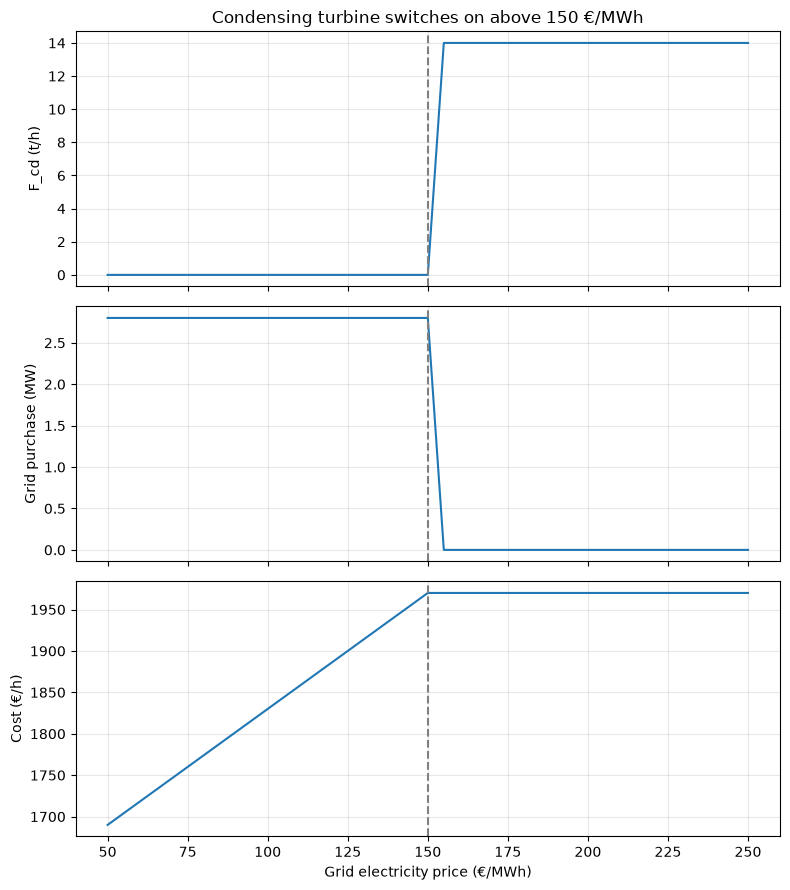

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

axes[0].plot(df["price"], df["F_cd"])
axes[0].set_ylabel("F_cd (t/h)")

axes[1].plot(df["price"], df["P_buy"])
axes[1].set_ylabel("Grid purchase (MW)")

axes[2].plot(df["price"], df["cost_eur_h"])
axes[2].set_ylabel("Cost (€/h)")
axes[2].set_xlabel("Grid electricity price (€/MWh)")

for ax in axes:
    ax.axvline(150, linestyle="--", color="grey")
    ax.grid(alpha=0.3)
axes[0].set_title("Condensing turbine switches on above 150 €/MWh")

fig.tight_layout()
fig.savefig("../docs/price_sweep.png", dpi=150)